In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import DBSCAN

# Generate datasets
D1 = make_blobs(n_samples=100, centers=2, cluster_std=1.0, random_state=7)
D2 = make_blobs(n_samples=200, centers=4, cluster_std=1.0, random_state=7)
D3 = make_moons(n_samples=200, noise=0.05, random_state=7)
D4 = make_circles(n_samples=200, noise=0.03, factor=0.5, random_state=7)
datasets = [D1, D2, D3, D4]

# Plotting function
def plot_clusters(ax, X, labels, title):
    is_noise = labels == -1
    ax.scatter(X[~is_noise, 0], X[~is_noise, 1], c=labels[~is_noise], s=10)
    ax.scatter(X[is_noise, 0], X[is_noise, 1], c="gray", marker="x")
    ax.set_title(title)

In [23]:
# 1: DBSCAN implementation
def my_dbscan(X, eps, min_pts):
    # pairwise Euclidean distances using numpy broadcasting
    # X[:, None] has shape (N, 1, D) and X[None] has shape (1, N, D)
    d = np.sqrt(((X[:, None] - X[None]) ** 2).sum(2))
    
    # Find all neighbors within the 'eps' radius 
    neighbors = d <= eps
    
    # Identify core points
    core_pts = neighbors.sum(1) >= min_pts
    
    labels = np.full(len(X), -1)
    
    c = 0
    
    # Iterate through all points to assign clusters
    for i in range(len(X)):
        # Skip points that are already in a cluster or are not core points
        if labels[i] != -1 or not core_pts[i]:
            continue
            
        # Start a new cluster
        labels[i] = c
        queue = [i] # Queue for BFS
        
        # Expand the cluster
        while queue:
            p = queue.pop(0)
            
            # Only core points can expand the cluster to their neighbors
            if core_pts[p]:
                # Get neighbors of 'p' that are still marked as noise (-1)
                new_pts = np.where(neighbors[p] & (labels == -1))[0]
                
                # Assign them to the current cluster
                labels[new_pts] = c
                
                # Add new points to the queue to check their neighbors later
                queue.extend(new_pts)
                
        # Move to the next cluster ID after the queue is empty
        c += 1
        
    return labels, core_pts

Dataset 1, eps 1.0: clusters 2, noise 2, ARI 0.96
  sklearn match: core True, noise True, ARI 1.00
Dataset 2, eps 1.0: clusters 4, noise 7, ARI 0.95
  sklearn match: core True, noise True, ARI 1.00
Dataset 3, eps 0.2: clusters 2, noise 0, ARI 1.00
  sklearn match: core True, noise True, ARI 1.00
Dataset 4, eps 0.2: clusters 2, noise 0, ARI 1.00
  sklearn match: core True, noise True, ARI 1.00
Dataset 4, eps 0.15: clusters 12, noise 6, ARI 0.54
  sklearn match: core True, noise True, ARI 1.00
Dataset 4, eps 0.3: clusters 2, noise 0, ARI 1.00
  sklearn match: core True, noise True, ARI 1.00


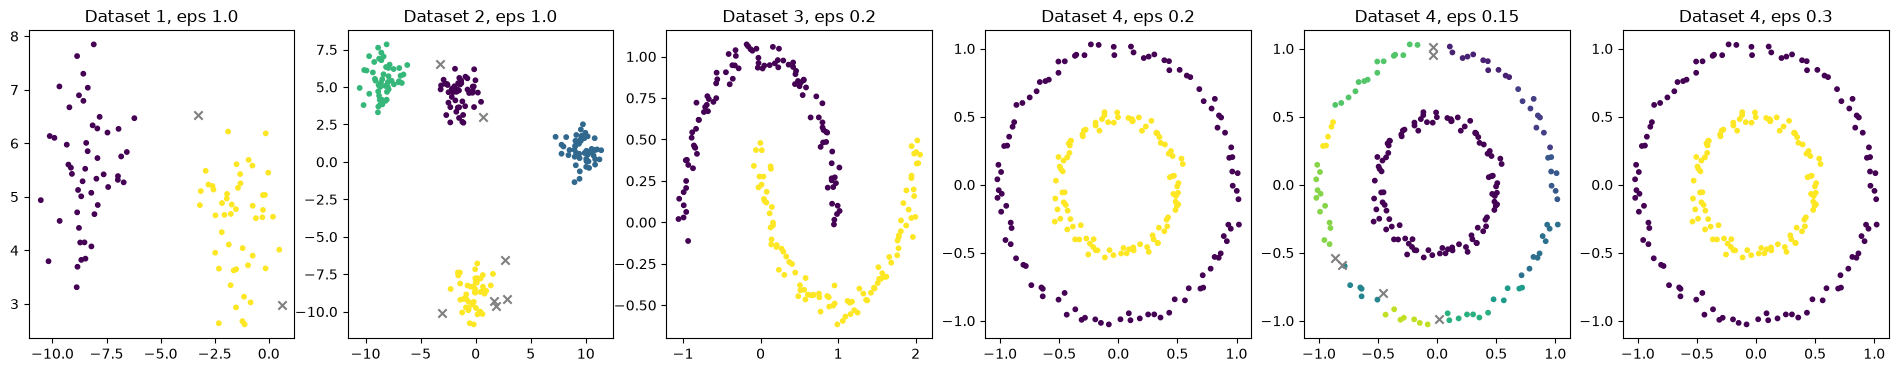

In [24]:
# Run DBSCAN and plot results
runs = [(0, 1.0), (1, 1.0), (2, 0.2), (3, 0.2), (3, 0.15), (3, 0.3)]
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for ax, (i, eps) in zip(axes, runs):
    X, y = datasets[i]
    labels, core = my_dbscan(X, eps, 5)
    sk = DBSCAN(eps=eps, min_samples=5).fit(X)
    
    print(f"Dataset {i + 1}, eps {eps}: clusters {labels.max() + 1}, noise {(labels == -1).sum()}, ARI {adjusted_rand_score(y, labels):.2f}")
    print(f"  sklearn match: core {np.array_equal(np.where(core)[0], sk.core_sample_indices_)}, noise {np.array_equal(labels == -1, sk.labels_ == -1)}, ARI {adjusted_rand_score(sk.labels_, labels):.2f}")
    plot_clusters(ax, X, labels, f"Dataset {i + 1}, eps {eps}")
plt.show()

In [25]:
# KMeans helper
def kmeans(X, K, rng, tol=1e-6, max_iter=300):
    
    init_indices = rng.choice(len(X), size=K, replace=False)
    centroids = X[init_indices].copy()
    
    j_history = []
    
    for _ in range(max_iter):
        # Distance calculation using broadcasting (same as X[:, None] - centroids[None])
        dists = np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
        
        labels = np.argmin(dists, axis=1)
        
        min_dists = np.min(dists, axis=1)
        J = np.sum(min_dists)
            
        j_history.append(J)
        
        if len(j_history) > 1 and (j_history[-2] - J) < tol:
            break
            
        # Update centroids
        new_centroids = np.zeros_like(centroids)
        for k in range(K):
            mask = (labels == k)
            if np.any(mask):
                new_centroids[k] = X[mask].mean(axis=0)
            else:
                new_centroids[k] = centroids[k] # Handle empty cluster
        centroids = new_centroids
        
    return labels, centroids, j_history

In [26]:
def spectral_clustering(X, K, sigma):
    # Calculate similarity matrix (W) with zero diagonal
    d2 = np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=2)
    W = np.exp(-d2 / (2 * sigma ** 2))
    np.fill_diagonal(W, 0)
    
    # Calculate degree matrix (D) and Laplacian (L)
    D = np.diag(W.sum(axis=1))
    L = D - W
    
    # Eigen decomposition
    vals, vecs = np.linalg.eigh(L)
    Vk = vecs[:, :K]
    
    # Run custom K-means 10 times and return the best result
    best_J = float('inf')
    best_labels = None
    
    rng = np.random.default_rng(0)
    
    for _ in range(10):
        labels, _, j_history = kmeans(Vk, K, rng)
        final_J = j_history[-1]
        
        if final_J < best_J:
            best_J = final_J
            best_labels = labels
            
    return best_labels, vals, Vk

Dataset 1, sigma 1.0: eigenvalues [0.0, 0.0022, 3.5978], ARI 1.00
Dataset 2, sigma 1.0: eigenvalues [-0.0, 0.0, 0.0, 0.0022, 0.8898], ARI 1.00
Dataset 3, sigma 0.1: eigenvalues [-0.0, 0.0, 0.0253], ARI 1.00
Dataset 4, sigma 0.1: eigenvalues [0.0, 0.0004, 0.0164], ARI 1.00
Dataset 4, sigma 0.2: eigenvalues [0.0, 0.4978, 0.5238], ARI -0.00


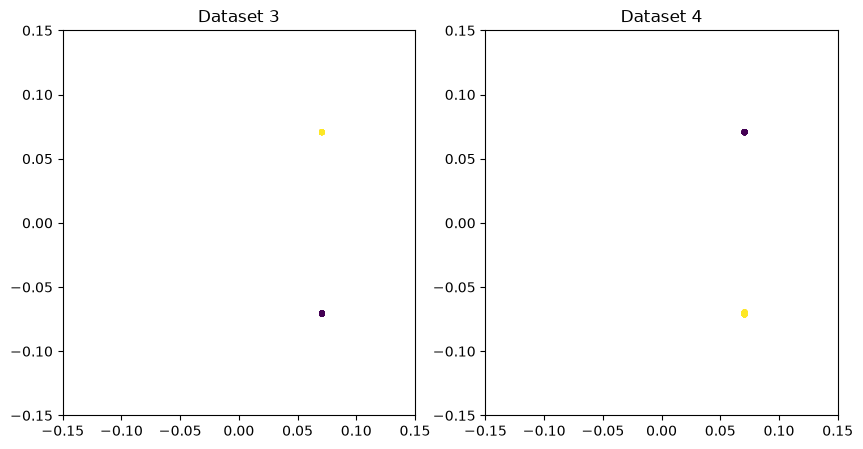

In [27]:
# Run spectral clustering
for i, sigma in [(0, 1.0), (1, 1.0), (2, 0.1), (3, 0.1), (3, 0.2)]:
    X, y = datasets[i]
    K = len(np.unique(y))
    labels, vals, Vk = spectral_clustering(X, K, sigma)
    print(f"Dataset {i + 1}, sigma {sigma}: eigenvalues {np.round(vals[:K + 1], 4).tolist()}, ARI {adjusted_rand_score(y, labels):.2f}")

# Plot spectral clustering results
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, i in zip(axes, (2, 3)):
    X, y = datasets[i]
    labels, vals, Vk = spectral_clustering(X, 2, 0.1)
    ax.scatter(Vk[:, 0], Vk[:, 1], c=labels, s=10)
    ax.set_xlim(-0.15, 0.15)
    ax.set_ylim(-0.15, 0.15)
    ax.set_title(f"Dataset {i + 1}")
plt.show()

In [28]:
# Task 3: Purity score
def purity_score(y, labels):
    correct = sum(np.bincount(y[labels == c]).max() for c in np.unique(labels) if c != -1)
    return correct / len(y)


--- ARI / PURITY COMPARISON ---
Dataset 1 | K-means:   ARI 1.00 / Purity 1.00
Dataset 1 | DBSCAN:    ARI 0.96 / Purity 0.98
Dataset 1 | Spectral:  ARI 1.00 / Purity 1.00
--------------------------------------------------
Dataset 2 | K-means:   ARI 0.63 / Purity 0.75
Dataset 2 | DBSCAN:    ARI 0.95 / Purity 0.96
Dataset 2 | Spectral:  ARI 1.00 / Purity 1.00
--------------------------------------------------
Dataset 3 | K-means:   ARI 0.24 / Purity 0.74
Dataset 3 | DBSCAN:    ARI 1.00 / Purity 1.00
Dataset 3 | Spectral:  ARI 1.00 / Purity 1.00
--------------------------------------------------
Dataset 4 | K-means:   ARI -0.00 / Purity 0.51
Dataset 4 | DBSCAN:    ARI 1.00 / Purity 1.00
Dataset 4 | Spectral:  ARI 1.00 / Purity 1.00
--------------------------------------------------


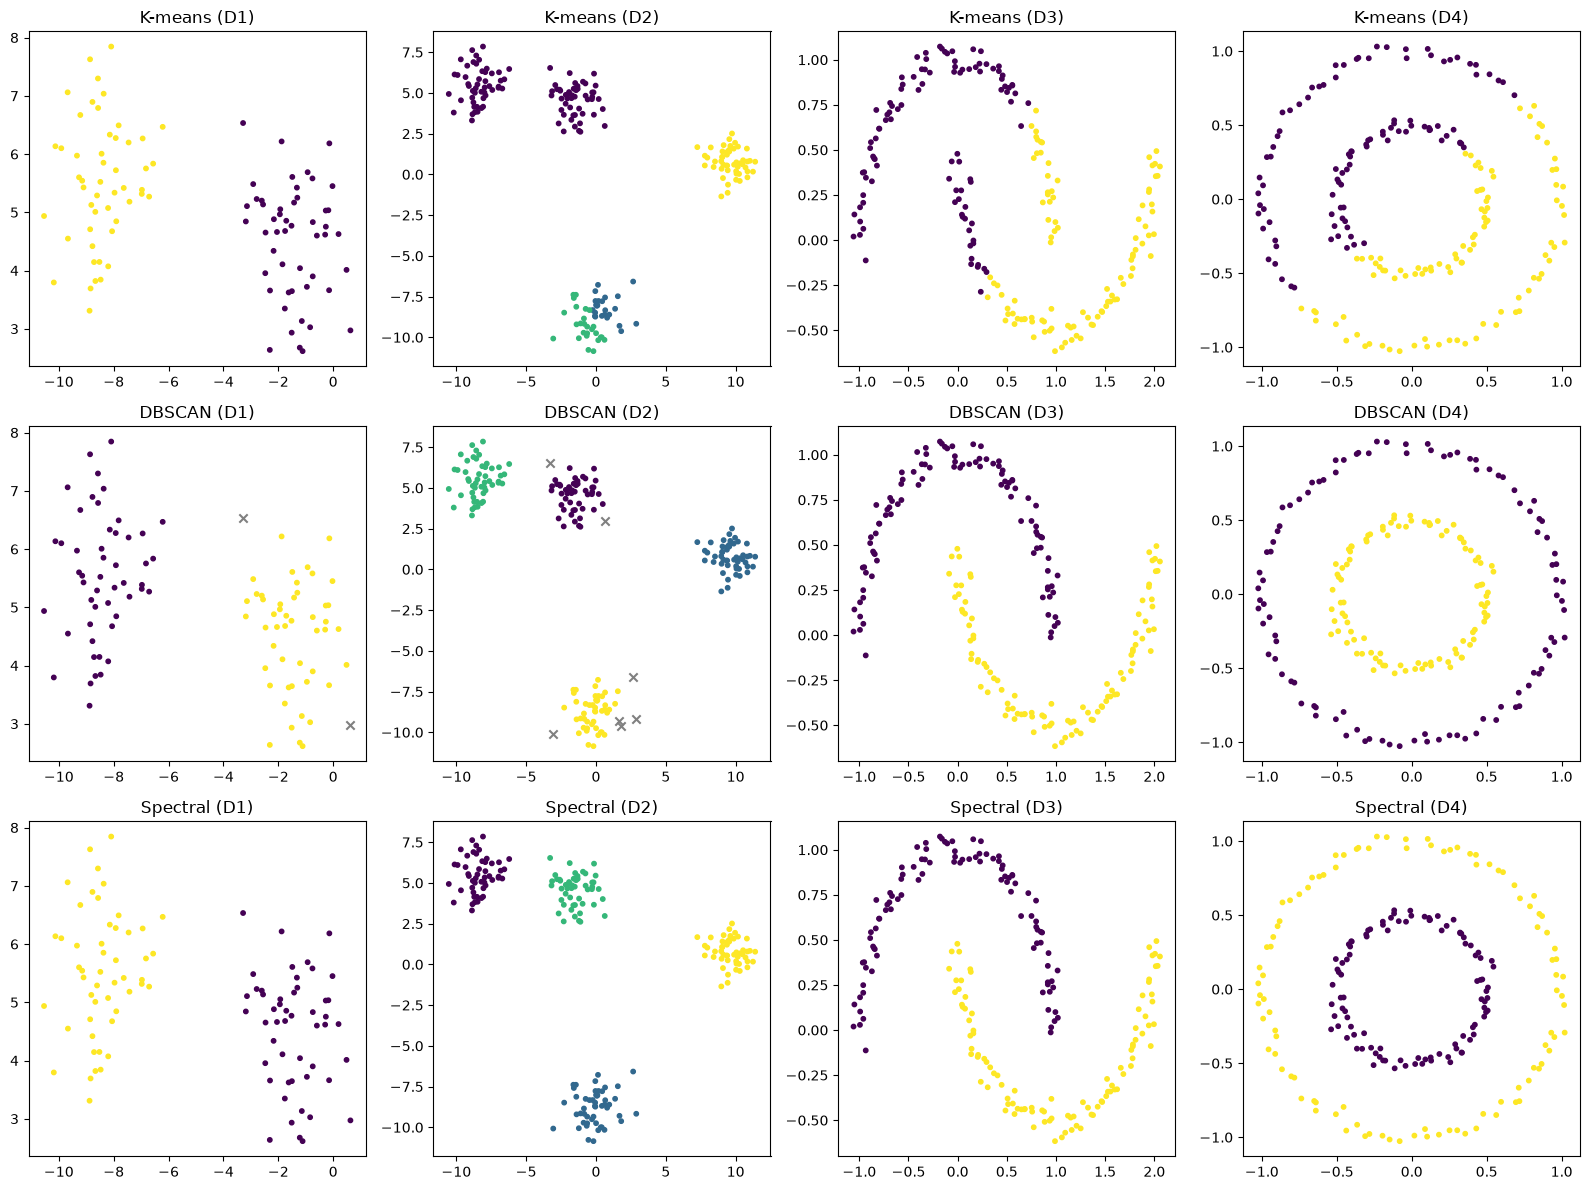

In [ ]:
# Compare K-means, DBSCAN, and Spectral Clustering in a 3x4 grid
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
params_dbscan = [1.0, 1.0, 0.2, 0.2]
params_spectral = [1.0, 1.0, 0.1, 0.1]
rng = np.random.default_rng(0)

print("\n--- ARI / PURITY COMPARISON ---")
for i in range(4):
    X, y = datasets[i]
    K = len(np.unique(y))
    
    # 1. K-means
    best_J = float('inf')
    km_labels = None
    for _ in range(10):
        labels, _, j_history = kmeans(X, K, rng)
        if j_history[-1] < best_J:
            best_J = j_history[-1]
            km_labels = labels
    plot_clusters(axes[0, i], X, km_labels, f"K-means (D{i+1})")
    print(f"Dataset {i+1} | K-means:   ARI {adjusted_rand_score(y, km_labels):.2f} / Purity {purity_score(y, km_labels):.2f}")
    
    # 2. DBSCAN
    db_labels, _ = my_dbscan(X, params_dbscan[i], 5)
    plot_clusters(axes[1, i], X, db_labels, f"DBSCAN (D{i+1})")
    print(f"Dataset {i+1} | DBSCAN:    ARI {adjusted_rand_score(y, db_labels):.2f} / Purity {purity_score(y, db_labels):.2f}")
    
    # 3. Spectral Clustering
    sp_labels, _, _ = spectral_clustering(X, K, params_spectral[i])
    plot_clusters(axes[2, i], X, sp_labels, f"Spectral (D{i+1})")
    print(f"Dataset {i+1} | Spectral:  ARI {adjusted_rand_score(y, sp_labels):.2f} / Purity {purity_score(y, sp_labels):.2f}")
    print("-" * 50)

plt.tight_layout()
plt.show()